# Round 3 — "Gloves Off" Data Analysis

Analysis of Round 3 packet data: `HYDROGEL_PACK`, `VELVETFRUIT_EXTRACT`, and 10 voucher options (`VEV_4000` – `VEV_6500`).

Sections:
1. Setup & data loading
2. Price-level exploration per product
3. Order book microstructure (spreads, walls, depth)
4. Underlying mean-reversion diagnostics (HYDROGEL & VEV)
5. Options: implied vol surface + smile fit
6. Theo-diff dynamics (the IV scalping signal)
7. Trade flow analysis
8. Strategy parameter sweeps

## 1. Setup

In [3]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
from statistics import NormalDist
from scipy.optimize import brentq
from pathlib import Path

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

_N = NormalDist()
DATA_DIR = Path('data/')
DAYS = [0, 1, 2]
DAYS_PER_YEAR = 365

STRIKES = [4000, 4500, 5000, 5100, 5200, 5300, 5400, 5500, 6000, 6500]
VOUCHERS = [f'VEV_{k}' for k in STRIKES]
UNDERLYING = 'VELVETFRUIT_EXTRACT'
HYDROGEL = 'HYDROGEL_PACK'

# Historical TTE: day 0 -> 8d, day 1 -> 7d, day 2 -> 6d
# Round 3 live -> DAY=3 -> TTE=5d at start

In [4]:
def load_prices(day):
    return pd.read_csv(DATA_DIR / f'prices_round_3_day_{day}.csv', sep=';')

def load_trades(day):
    return pd.read_csv(DATA_DIR / f'trades_round_3_day_{day}.csv', sep=';')

prices = {d: load_prices(d) for d in DAYS}
trades = {d: load_trades(d) for d in DAYS}

# Stack all 3 days with continuous timestamps so we can analyse cross-day
prices_all = pd.concat([
    prices[d].assign(global_ts=prices[d]['timestamp'] + d * 1_000_000)
    for d in DAYS
], ignore_index=True)

print('prices shape per day:', {d: prices[d].shape for d in DAYS})
print('trades shape per day:', {d: trades[d].shape for d in DAYS})
print('products in prices:', sorted(prices_all['product'].unique()))
prices[0].head()

prices shape per day: {0: (120000, 17), 1: (120000, 17), 2: (120000, 17)}
trades shape per day: {0: (1308, 7), 1: (1407, 7), 2: (1333, 7)}
products in prices: ['HYDROGEL_PACK', 'VELVETFRUIT_EXTRACT', 'VEV_4000', 'VEV_4500', 'VEV_5000', 'VEV_5100', 'VEV_5200', 'VEV_5300', 'VEV_5400', 'VEV_5500', 'VEV_6000', 'VEV_6500']


,day,timestamp,product,bid_price_1,bid_volume_1,bid_price_2,bid_volume_2,bid_price_3,bid_volume_3,ask_price_1,ask_volume_1,ask_price_2,ask_volume_2,ask_price_3,ask_volume_3,mid_price,profit_and_loss
0,0,0,VEV_5400,22,25,NaN,NaN,NaN,NaN,24,25,NaN,NaN,NaN,NaN,23.0,0.0
1,0,0,VEV_6500,0,16,NaN,NaN,NaN,NaN,1,16,NaN,NaN,NaN,NaN,0.5,0.0
2,0,0,VEV_5500,8,25,NaN,NaN,NaN,NaN,9,25,NaN,NaN,NaN,NaN,8.5,0.0
3,0,0,VEV_5200,100,19,NaN,NaN,NaN,NaN,103,6,104.0,13.0,NaN,NaN,101.5,0.0
4,0,0,VEV_5300,52,6,51.0,19.0,NaN,NaN,54,25,NaN,NaN,NaN,NaN,53.0,0.0


In [10]:
# Pivot helpers: one column per product, indexed by (day, timestamp)
def pivot_field(field='mid_price'):
    return prices_all.pivot_table(index=['day', 'timestamp'], columns='product', values=field)

mid_pivot = pivot_field('mid_price')
bb1_pivot = pivot_field('bid_price_1')
ba1_pivot = pivot_field('ask_price_1')
bv1_pivot = pivot_field('bid_volume_1')
av1_pivot = pivot_field('ask_volume_1')

mid_pivot.head()


product        HYDROGEL_PACK  VELVETFRUIT_EXTRACT  VEV_4000  VEV_4500  \
day timestamp                                                           
0   0                10000.0               5250.0    1250.0     750.0   
    100              10000.0               5250.5    1250.5     751.0   
    200              10003.0               5250.5    1250.5     750.0   
    300              10002.0               5250.5    1250.5     750.0   
    400              10003.0               5250.5    1250.5     750.0   

product        VEV_5000  VEV_5100  VEV_5200  VEV_5300  VEV_5400  VEV_5500  \
day timestamp                                                               
0   0             257.0     171.5     101.5      53.0      23.0       8.5   
    100           258.0     172.0     102.5      53.0      23.5       8.5   
    200           257.0     172.0     102.5      53.0      23.5       8.5   
    300           257.5     172.0     102.5      53.0      23.5       8.5   
    400           257.0     172.0     102.5      53.0      23.5       8.5   

product        VEV_6000  VEV_6500  
day timestamp                      
0   0               0.5       0.5  
    100             0.5       0.5  
    200             0.5       0.5  
    300             0.5       0.5  
    400             0.5       0.5

## 2. Price-level exploration

Per-product mid-price summary stats and time series.

In [6]:
# Summary statistics per (product, day)
summary = prices_all.groupby(['product', 'day'])['mid_price'].agg(['mean', 'std', 'min', 'max']).round(2)
summary

mean    std     min      max
product             day                                 
HYDROGEL_PACK       0    9990.96  25.33  9928.0  10071.0
                    1    9992.06  37.61  9908.5  10079.0
                    2    9989.40  31.62  9891.0  10051.0
VELVETFRUIT_EXTRACT 0    5246.51  13.68  5216.5   5284.5
                    1    5248.39  14.61  5198.0   5283.0
                    2    5255.39  16.99  5207.0   5300.0
VEV_4000            0    1246.52  13.70  1215.0   1285.0
                    1    1248.41  14.63  1198.0   1283.0
                    2    1255.40  17.00  1207.0   1300.0
VEV_4500            0     746.52  13.69   716.5    785.0
                    1     748.41  14.63   698.5    783.0
                    2     755.40  16.99   708.5    799.5
VEV_5000            0     253.26  12.49   226.0    289.0
                    1     253.26  13.58   206.5    285.5
                    2     258.54  16.15   213.5    300.5
VEV_5100            0     168.11  10.95   145.0    200.5
                    1     164.98  11.94   125.0    193.5
                    2     167.33  14.81   127.5    205.5
VEV_5200            0      97.47   8.17    80.5    122.5
                    1      95.13   8.66    66.0    116.0
                    2      94.05  11.50    64.0    122.5
VEV_5300            0      48.89   5.18    38.0     65.5
                    1      46.91   5.47    30.0     61.0
                    2      44.48   7.06    26.5     60.5
VEV_5400            0      18.47   2.78    11.5     27.0
                    1      15.65   2.68     7.5     23.0
                    2      13.73   3.01     6.5     21.5
VEV_5500            0       8.06   1.24     5.5     12.5
                    1       6.57   1.33     3.0     10.0
                    2       5.29   1.40     2.5      9.5
VEV_6000            0       0.50   0.00     0.5      0.5
                    1       0.50   0.00     0.5      0.5
                    2       0.50   0.00     0.5      0.5
VEV_6500            0       0.50   0.00     0.5      0.5
                    1       0.50   0.00     0.5      0.5
                    2       0.50   0.00     0.5      0.5

UFuncTypeError: ufunc 'add' did not contain a loop with signature matching types (dtype('<U32'), dtype('<U32')) -> None

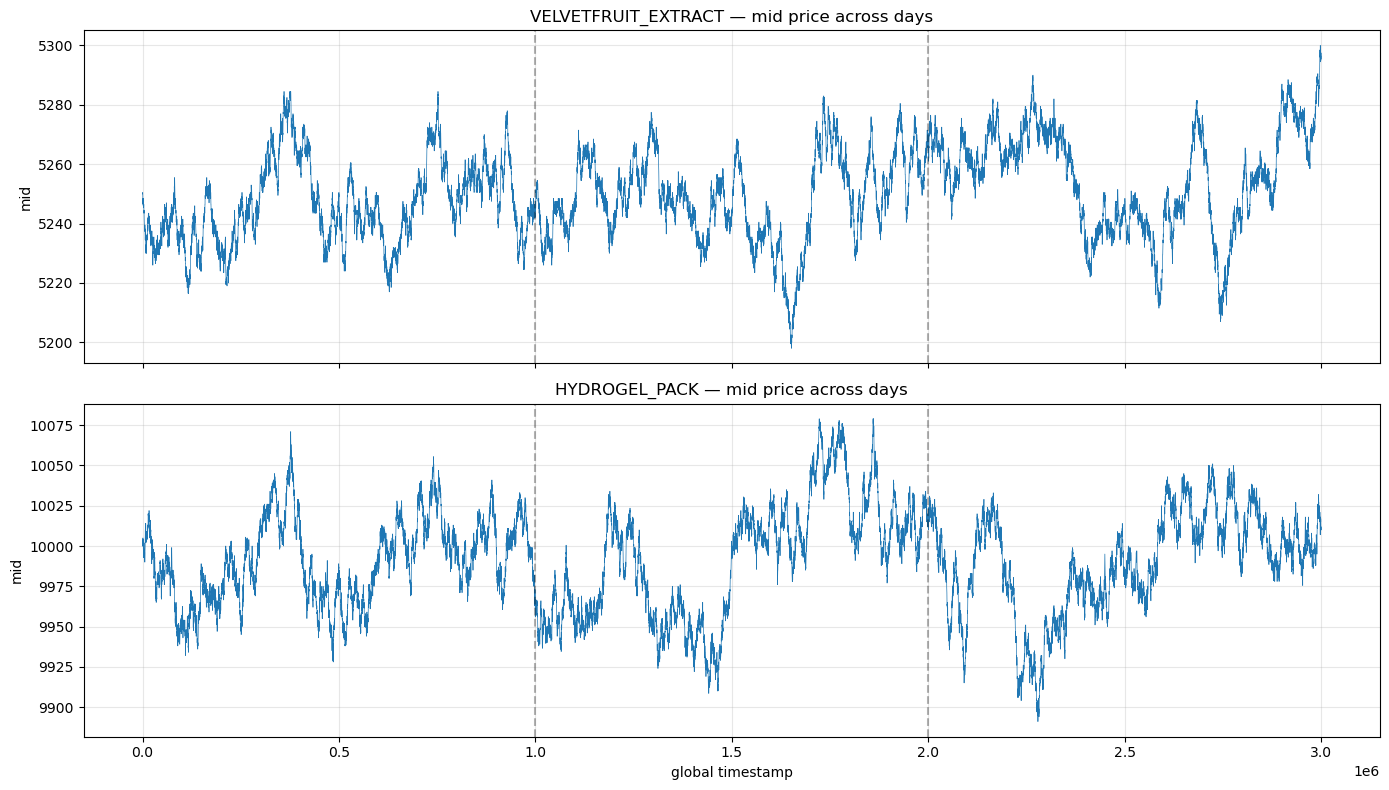

In [ ]:
# Plot the two underlyings across all 3 days
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for ax, prod in zip(axes, [UNDERLYING, HYDROGEL]):
    series = prices_all[prices_all['product'] == prod].sort_values('global_ts')
    ax.plot(series['global_ts'], series['mid_price'], lw=0.5)
    for d in [1, 2]:
        ax.axvline(d * 1_000_000, color='k', ls='--', alpha=0.3)
    ax.set_title(f'{prod} — mid price across days')
    ax.set_ylabel('mid')
axes[-1].set_xlabel('global timestamp')
plt.tight_layout()

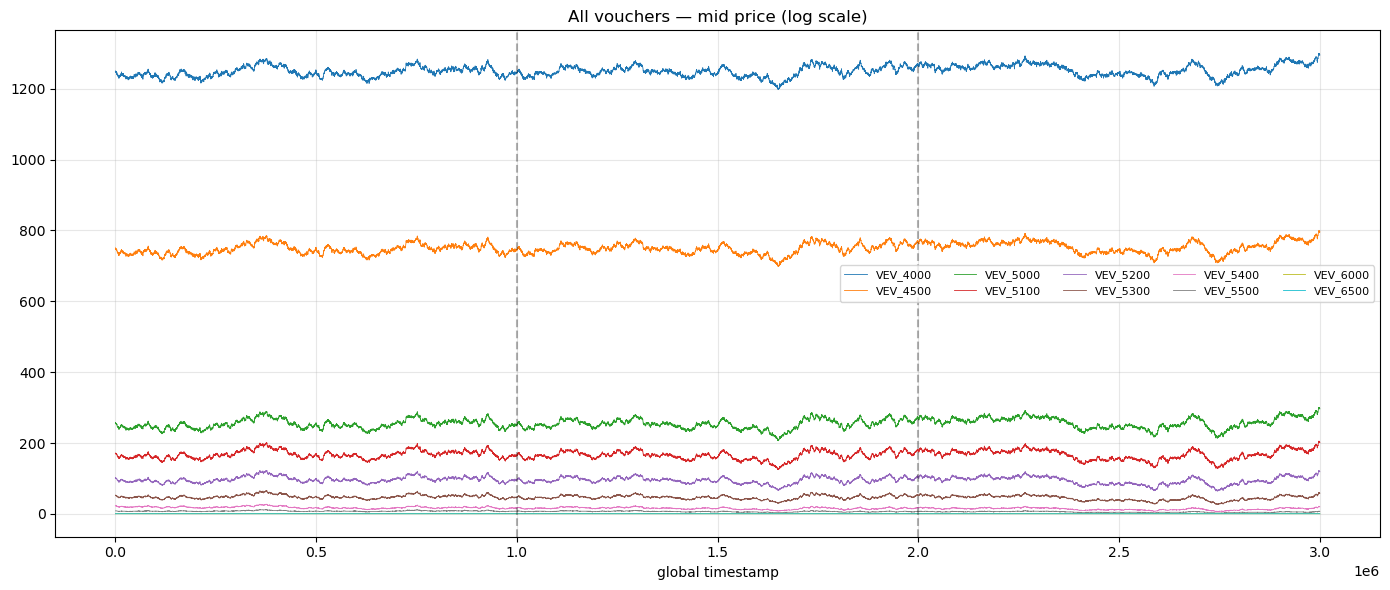

In [ ]:
# Plot all vouchers — log-scaled because they span several orders of magnitude
fig, ax = plt.subplots(figsize=(14, 6))
for v in VOUCHERS:
    sub = prices_all[prices_all['product'] == v].sort_values('global_ts')
    if len(sub) > 0:
        ax.plot(sub['global_ts'], sub['mid_price'], lw=0.6, label=v)
for d in [1, 2]:
    ax.axvline(d * 1_000_000, color='k', ls='--', alpha=0.3)
ax.set_yscale('log')
ax.set_title('All vouchers — mid price (log scale)')
ax.set_xlabel('global timestamp')
ax.legend(ncol=5, fontsize=8)
plt.tight_layout()

## 3. Order book microstructure

In [ ]:
# Average spread, wall-mid spread, depth per product
rows = []
for prod in prices_all['product'].unique():
    sub = prices_all[prices_all['product'] == prod].copy()
    inner_spread = (sub['ask_price_1'] - sub['bid_price_1']).dropna()
    # Wall = furthest-out level present (could be lvl 1, 2 or 3)
    bid_walls = sub[['bid_price_1', 'bid_price_2', 'bid_price_3']].min(axis=1)
    ask_walls = sub[['ask_price_1', 'ask_price_2', 'ask_price_3']].max(axis=1)
    wall_spread = (ask_walls - bid_walls).dropna()
    depth_bid = sub[['bid_volume_1', 'bid_volume_2', 'bid_volume_3']].sum(axis=1).mean()
    depth_ask = sub[['ask_volume_1', 'ask_volume_2', 'ask_volume_3']].sum(axis=1).mean()
    rows.append({
        'product': prod,
        'inner_spread_mean': round(inner_spread.mean(), 3),
        'inner_spread_std': round(inner_spread.std(), 3),
        'wall_spread_mean': round(wall_spread.mean(), 3),
        'avg_bid_depth': round(depth_bid, 1),
        'avg_ask_depth': round(depth_ask, 1),
    })
ob_summary = pd.DataFrame(rows).sort_values('inner_spread_mean', ascending=False).reset_index(drop=True)
ob_summary

,product,inner_spread_mean,inner_spread_std,wall_spread_mean,avg_bid_depth,avg_ask_depth
0,VEV_4000,20.813,1.482,25.998,33.5,33.5
1,VEV_4500,15.853,1.189,19.753,27.0,27.0
2,HYDROGEL_PACK,15.721,1.455,20.980,37.6,37.6
3,VEV_5000,6.043,0.646,7.375,27.0,27.0
4,VELVETFRUIT_EXTRACT,4.988,0.847,6.250,60.4,60.4
5,VEV_5100,4.296,0.580,5.175,27.0,27.0
6,VEV_5200,2.888,0.443,3.389,27.0,27.0
7,VEV_5300,2.107,0.390,2.403,22.5,22.5
8,VEV_5400,1.381,0.486,1.479,22.5,22.5
9,VEV_5500,1.150,0.357,1.190,22.5,22.5


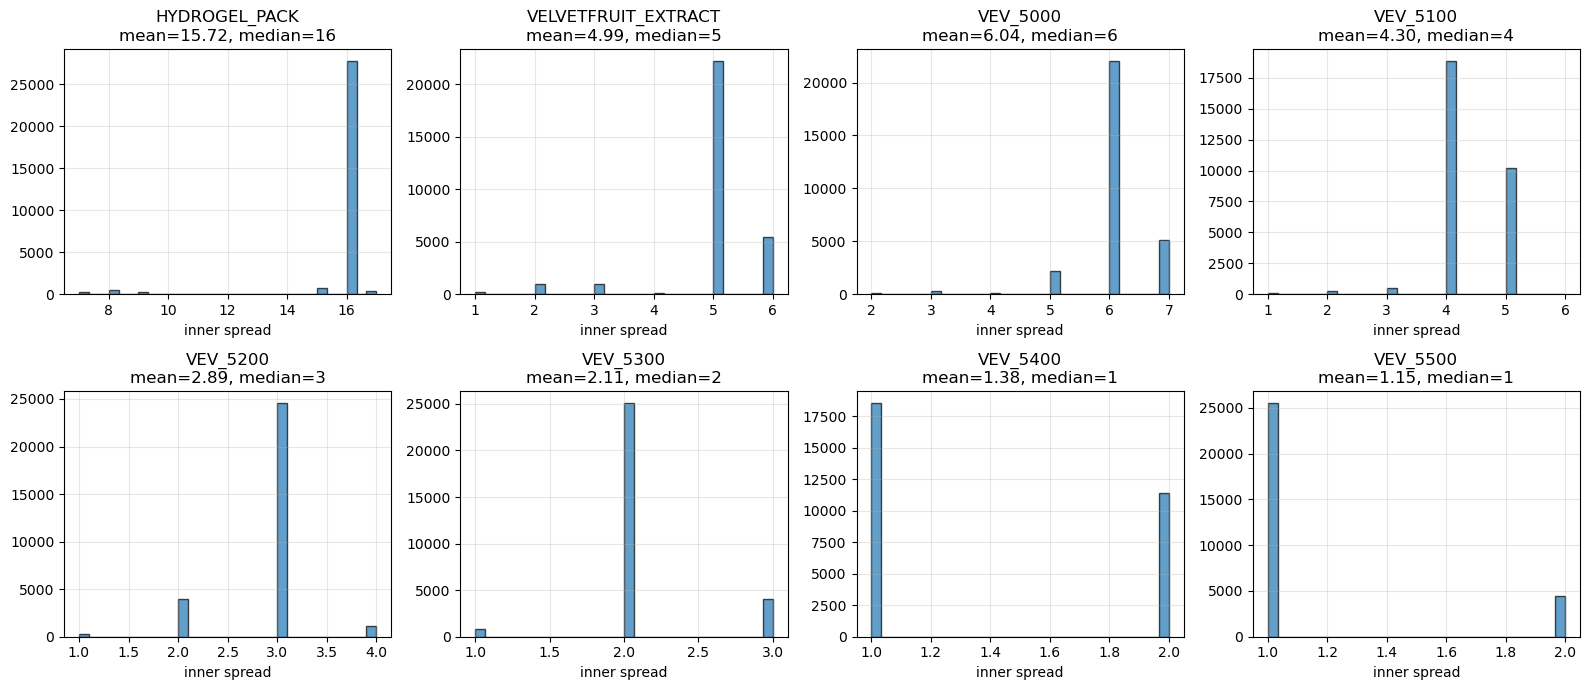

In [ ]:
# Distribution of inner spread for the products we actually trade
traded = [HYDROGEL, UNDERLYING] + [f'VEV_{k}' for k in [5000, 5100, 5200, 5300, 5400, 5500]]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, prod in zip(axes.flat, traded):
    sub = prices_all[prices_all['product'] == prod]
    sp = (sub['ask_price_1'] - sub['bid_price_1']).dropna()
    if len(sp) == 0:
        ax.set_visible(False)
        continue
    ax.hist(sp, bins=30, edgecolor='black', alpha=0.7)
    ax.set_title(f'{prod}\nmean={sp.mean():.2f}, median={sp.median():.0f}')
    ax.set_xlabel('inner spread')
plt.tight_layout()

## 4. Mean reversion diagnostics

Both `HYDROGEL_PACK` and `VELVETFRUIT_EXTRACT` showed negative return autocorrelation in the strategy build. Quantify it and check the EMA window the strategy uses (10) is reasonable.

In [ ]:
def mr_diagnostics(product):
    rows = []
    for d in DAYS:
        s = prices[d][prices[d]['product'] == product].sort_values('timestamp')['mid_price'].values
        if len(s) < 50:
            continue
        rets = np.diff(s)
        # autocorr at lags 1..5
        acs = [np.corrcoef(rets[:-k], rets[k:])[0, 1] for k in range(1, 6)]
        rows.append({
            'day': d,
            'mean_return': rets.mean(),
            'std_return': rets.std(),
            'ac_lag1': acs[0],
            'ac_lag2': acs[1],
            'ac_lag5': acs[4],
        })
    return pd.DataFrame(rows).round(4)

print('--- HYDROGEL_PACK ---')
print(mr_diagnostics(HYDROGEL))
print('\n--- VELVETFRUIT_EXTRACT ---')
print(mr_diagnostics(UNDERLYING))

--- HYDROGEL_PACK ---
   day  mean_return  std_return  ac_lag1  ac_lag2  ac_lag5
0    0      -0.0042      2.1911  -0.1379  -0.0085  -0.0038
1    1       0.0057      2.1482  -0.1240   0.0113   0.0044
2    2      -0.0001      2.1698  -0.1254   0.0215   0.0045

--- VELVETFRUIT_EXTRACT ---
   day  mean_return  std_return  ac_lag1  ac_lag2  ac_lag5
0    0      -0.0006      1.1205  -0.1510   0.0156   0.0064
1    1       0.0021      1.1348  -0.1693  -0.0027  -0.0057
2    2       0.0028      1.1381  -0.1551   0.0022   0.0038


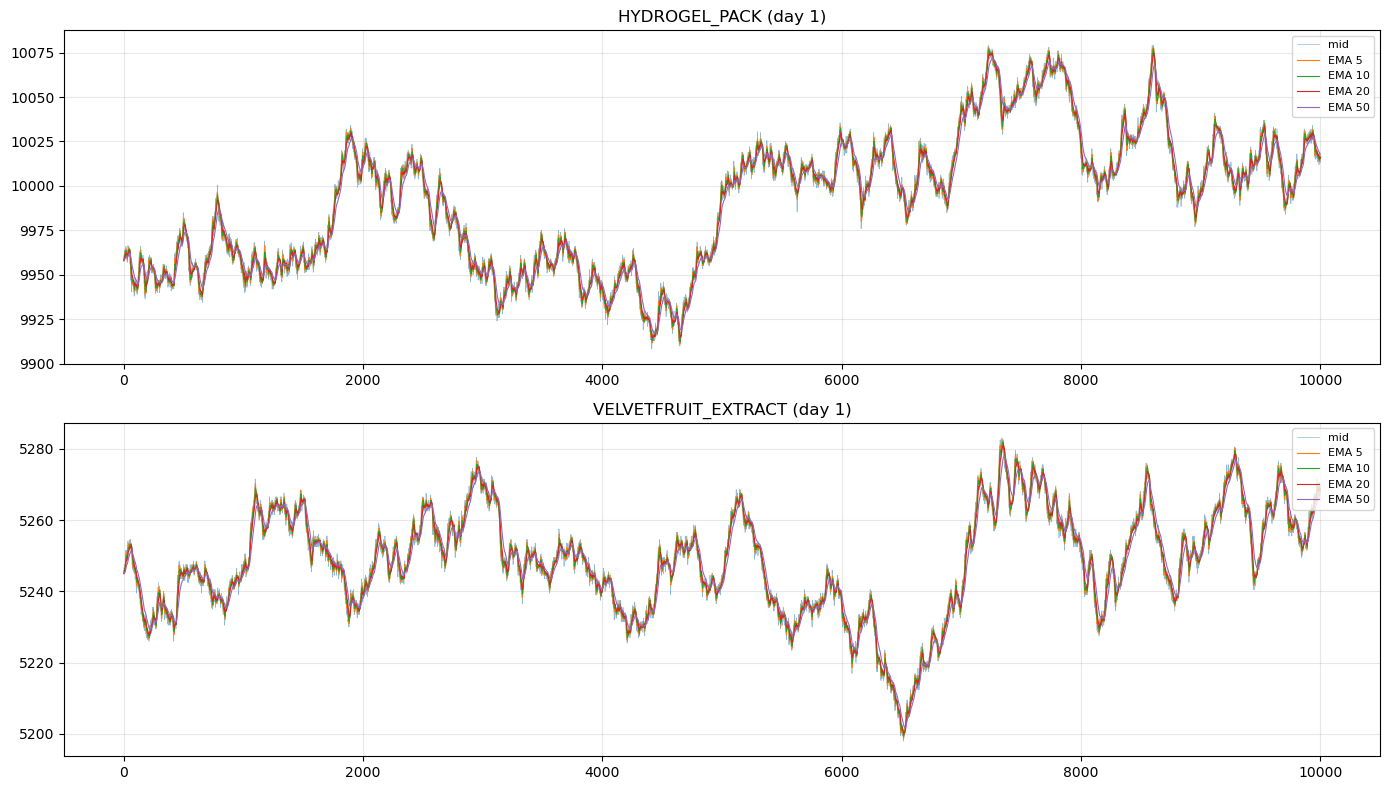

In [ ]:
# How well does an EMA fair value track the actual mid? Try a few windows.
def ema(values, window):
    alpha = 2 / (window + 1)
    out = np.zeros_like(values, dtype=float)
    out[0] = values[0]
    for i in range(1, len(values)):
        out[i] = alpha * values[i] + (1 - alpha) * out[i - 1]
    return out

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)
for ax, prod in zip(axes, [HYDROGEL, UNDERLYING]):
    sub = prices[1][prices[1]['product'] == prod].sort_values('timestamp')
    mid = sub['mid_price'].values
    ax.plot(mid, lw=0.5, label='mid', alpha=0.5)
    for w in [5, 10, 20, 50]:
        ax.plot(ema(mid, w), lw=0.8, label=f'EMA {w}')
    ax.set_title(f'{prod} (day 1)')
    ax.legend(loc='upper right', fontsize=8)
plt.tight_layout()

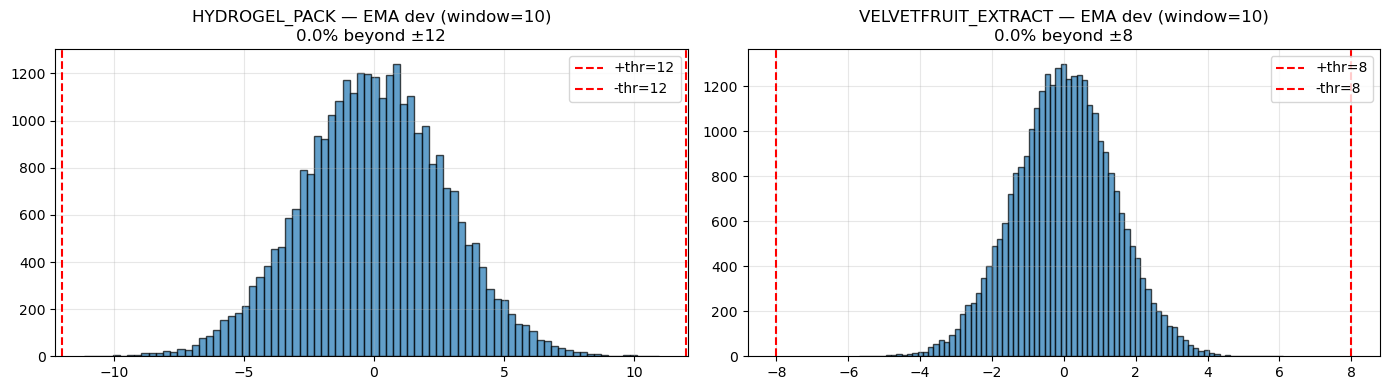

In [ ]:
# Distribution of EMA deviation: how often do we cross the strategy's MR threshold?
def deviation_stats(product, window):
    devs_all = []
    for d in DAYS:
        s = prices[d][prices[d]['product'] == product].sort_values('timestamp')['mid_price'].values
        if len(s) < window:
            continue
        e = ema(s, window)
        devs_all.append(s - e)
    return np.concatenate(devs_all) if devs_all else np.array([])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, prod, thr in zip(axes, [HYDROGEL, UNDERLYING], [12, 8]):
    devs = deviation_stats(prod, 10)
    ax.hist(devs, bins=80, edgecolor='black', alpha=0.7)
    ax.axvline(thr, color='red', ls='--', label=f'+thr={thr}')
    ax.axvline(-thr, color='red', ls='--', label=f'-thr={thr}')
    pct_signal = (np.abs(devs) > thr).mean() * 100
    ax.set_title(f'{prod} — EMA dev (window=10)\n{pct_signal:.1f}% beyond ±{thr}')
    ax.legend()
plt.tight_layout()

## 5. Implied vol surface and smile fit

Invert each voucher's mid price to an implied vol, then fit a quadratic in `m_t_k = log(K/S) / sqrt(T)`.

In [ ]:
def bs_call(S, K, T, sigma):
    if T <= 0 or sigma <= 0:
        return max(S - K, 0.0)
    d1 = (math.log(S/K) + 0.5 * sigma**2 * T) / (sigma * T**0.5)
    d2 = d1 - sigma * T**0.5
    return S * _N.cdf(d1) - K * _N.cdf(d2)

def implied_vol(price, S, K, T):
    intrinsic = max(S - K, 0.0)
    if price <= intrinsic + 1e-6:
        return None
    try:
        return brentq(lambda s: bs_call(S, K, T, s) - price, 1e-4, 5.0, maxiter=100)
    except Exception:
        return None

def bs_vega(S, K, T, sigma):
    if T <= 0 or sigma <= 0:
        return 0.0
    d1 = (math.log(S/K) + 0.5 * sigma**2 * T) / (sigma * T**0.5)
    return S * _N.pdf(d1) * T**0.5

In [ ]:
# Build a long-form IV table: one row per (day, ts, K)
iv_rows = []
for d in DAYS:
    pv = prices[d].pivot_table(index='timestamp', columns='product', values='mid_price')
    if UNDERLYING not in pv.columns:
        continue
    tte_yr = (8 - d) / DAYS_PER_YEAR
    # Subsample every 25 ts to keep this fast
    for ts in pv.index[::25]:
        S = pv.loc[ts, UNDERLYING]
        if pd.isna(S):
            continue
        for K in STRIKES:
            col = f'VEV_{K}'
            if col not in pv.columns:
                continue
            price = pv.loc[ts, col]
            if pd.isna(price):
                continue
            iv = implied_vol(price, S, K, tte_yr)
            if iv is None or not (0.05 < iv < 1.5):
                continue
            m_t_k = math.log(K / S) / tte_yr**0.5
            iv_rows.append({
                'day': d, 'timestamp': ts, 'K': K, 'S': S,
                'tte_yr': tte_yr, 'price': price,
                'm_t_k': m_t_k, 'iv': iv,
            })
iv_df = pd.DataFrame(iv_rows)
print(f'{len(iv_df)} IV points')
iv_df.head()

10054 IV points


,day,timestamp,K,S,tte_yr,price,m_t_k,iv
0,0,0,5000,5250.0,0.021918,257.0,-0.329559,0.239329
1,0,0,5100,5250.0,0.021918,171.5,-0.195800,0.240052
2,0,0,5200,5250.0,0.021918,101.5,-0.064638,0.239229
3,0,0,5300,5250.0,0.021918,53.0,0.064025,0.241951
4,0,0,5400,5250.0,0.021918,23.0,0.190284,0.239881


In [ ]:
# Fit a quadratic smile across all data
coeffs_all = np.polyfit(iv_df['m_t_k'], iv_df['iv'], 2)
fit_all = np.poly1d(coeffs_all)
print('All-data quadratic fit:')
print(f'  IV(m) = {coeffs_all[0]:+.6f}*m^2 + {coeffs_all[1]:+.6f}*m + {coeffs_all[2]:+.6f}')
print(f'  ATM IV (m=0) = {coeffs_all[2]:.4f}')
resid = iv_df['iv'].values - fit_all(iv_df['m_t_k'].values)
print(f'  residual std = {resid.std():.4f}')

# Per-day fits — does the smile drift across days?
print('\nPer-day fits:')
for d in DAYS:
    sub = iv_df[iv_df['day'] == d]
    if len(sub) < 10:
        continue
    c = np.polyfit(sub['m_t_k'], sub['iv'], 2)
    print(f'  Day {d}: a={c[0]:+.4f}, b={c[1]:+.4f}, c={c[2]:.4f} (n={len(sub)})')

All-data quadratic fit:
  IV(m) = +0.147761*m^2 + -0.001323*m + +0.226886
  ATM IV (m=0) = 0.2269
  residual std = 0.0176

Per-day fits:
  Day 0: a=+0.1538, b=-0.0062, c=0.2267 (n=3357)
  Day 1: a=+0.1501, b=-0.0036, c=0.2271 (n=3358)
  Day 2: a=+0.1427, b=+0.0039, c=0.2262 (n=3339)


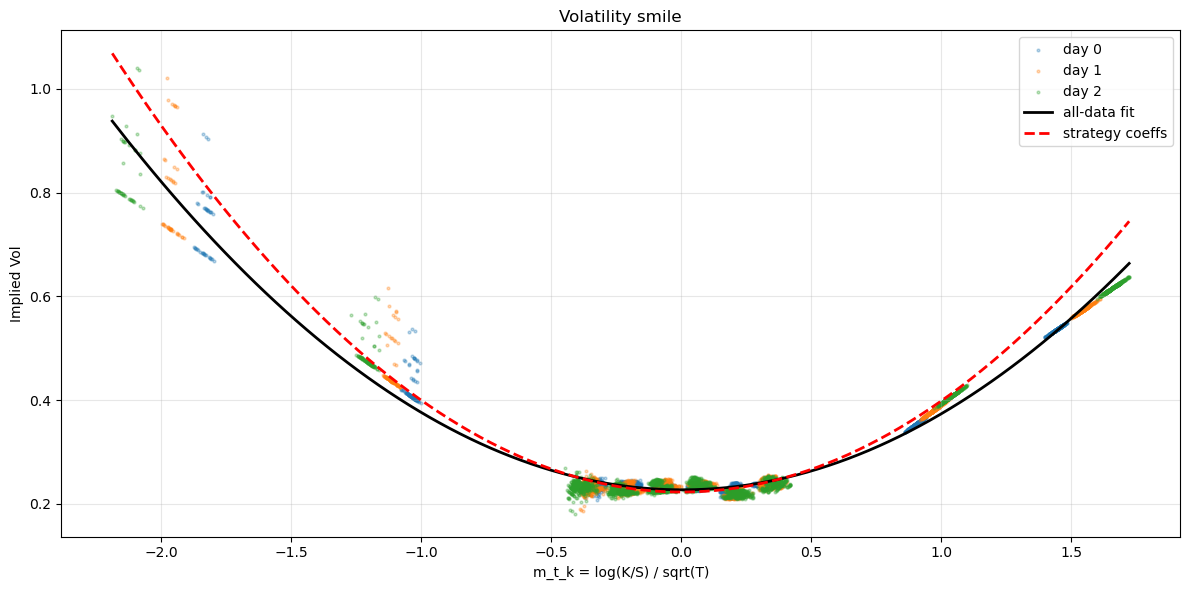

In [ ]:
# Plot the smile + fit
fig, ax = plt.subplots(figsize=(12, 6))
for d, color in zip(DAYS, ['C0', 'C1', 'C2']):
    sub = iv_df[iv_df['day'] == d]
    ax.scatter(sub['m_t_k'], sub['iv'], s=4, alpha=0.3, color=color, label=f'day {d}')
m_grid = np.linspace(iv_df['m_t_k'].min(), iv_df['m_t_k'].max(), 200)
ax.plot(m_grid, fit_all(m_grid), 'k-', lw=2, label='all-data fit')
# Currently used coeffs in strategy
STRATEGY_COEFFS = [0.17619891, -0.00067928, 0.22260638]
ax.plot(m_grid, np.poly1d(STRATEGY_COEFFS)(m_grid), 'r--', lw=2, label='strategy coeffs')
ax.set_xlabel('m_t_k = log(K/S) / sqrt(T)')
ax.set_ylabel('Implied Vol')
ax.set_title('Volatility smile')
ax.legend()
plt.tight_layout()

        mean     std  count
K                          
4000  0.7911  0.0862    128
4500  0.4504  0.0423    328
5000  0.2329  0.0085   1198
5100  0.2307  0.0076   1200
5200  0.2333  0.0062   1200
5300  0.2358  0.0056   1200
5400  0.2211  0.0071   1200
5500  0.2399  0.0062   1200
6000  0.3796  0.0219   1200
6500  0.5752  0.0329   1200


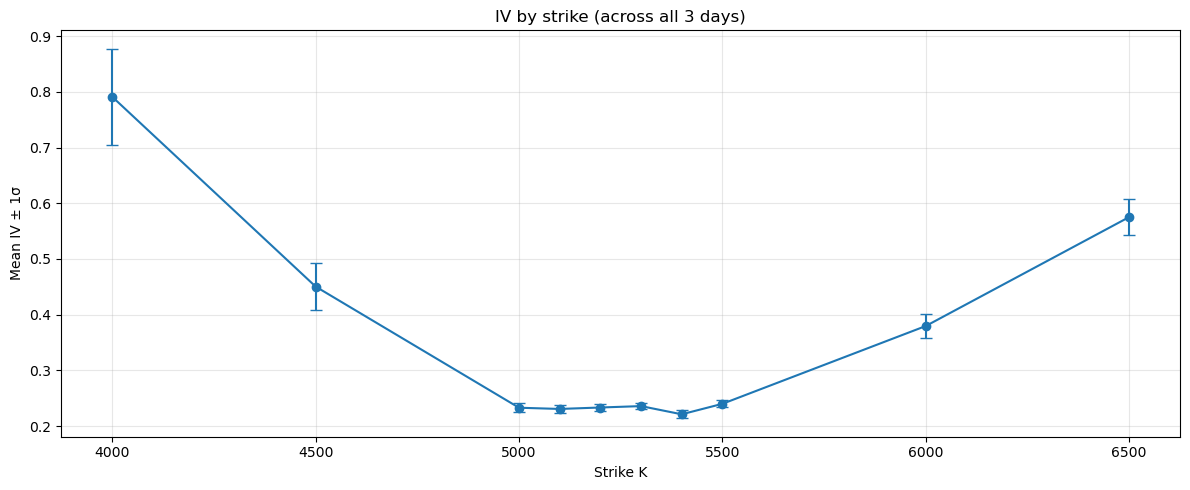

In [ ]:
# Smile per strike — see where mispricing is most stable
fig, ax = plt.subplots(figsize=(12, 5))
k_summary = iv_df.groupby('K')['iv'].agg(['mean', 'std', 'count']).round(4)
print(k_summary)
ax.errorbar(k_summary.index, k_summary['mean'], yerr=k_summary['std'],
            marker='o', capsize=4)
ax.set_xlabel('Strike K')
ax.set_ylabel('Mean IV ± 1σ')
ax.set_title('IV by strike (across all 3 days)')
plt.tight_layout()

## 6. Theo-diff dynamics — the IV scalping signal

The strategy trades on (market mid − BS theo from the smile). Look at how that diff behaves: how often it crosses the 0.5 threshold, how mean-reverting it is.

In [ ]:
# Compute theo and theo_diff at every timestamp using the strategy's smile
def smile_iv(S, K, T, coeffs):
    m_t_k = math.log(K / S) / T**0.5
    return float(np.poly1d(coeffs)(m_t_k))

theo_records = []
for d in DAYS:
    pv = prices[d].pivot_table(index='timestamp', columns='product', values='mid_price')
    if UNDERLYING not in pv.columns:
        continue
    tte_yr = (8 - d) / DAYS_PER_YEAR
    for ts in pv.index:
        S = pv.loc[ts, UNDERLYING]
        if pd.isna(S):
            continue
        for K in [5000, 5100, 5200, 5300, 5400, 5500]:
            col = f'VEV_{K}'
            if col not in pv.columns:
                continue
            mkt = pv.loc[ts, col]
            if pd.isna(mkt):
                continue
            sigma = smile_iv(S, K, tte_yr, STRATEGY_COEFFS)
            theo = bs_call(S, K, tte_yr, sigma)
            vega = bs_vega(S, K, tte_yr, sigma)
            theo_records.append({
                'day': d, 'timestamp': ts, 'K': K, 'S': S,
                'mkt': mkt, 'theo': theo, 'theo_diff': mkt - theo,
                'vega': vega,
            })
theo_df = pd.DataFrame(theo_records)
print(f'{len(theo_df)} theo records')
theo_df.head()

180000 theo records


,day,timestamp,K,S,mkt,theo,theo_diff,vega
0,0,0,5000,5250.0,257.0,257.312479,-0.312479,119.670029
1,0,0,5100,5250.0,171.5,169.221842,2.278158,212.346828
2,0,0,5200,5250.0,101.5,96.799299,4.700701,295.903147
3,0,0,5300,5250.0,53.0,47.401879,5.598121,298.959769
4,0,0,5400,5250.0,23.0,20.507286,2.492714,222.538859


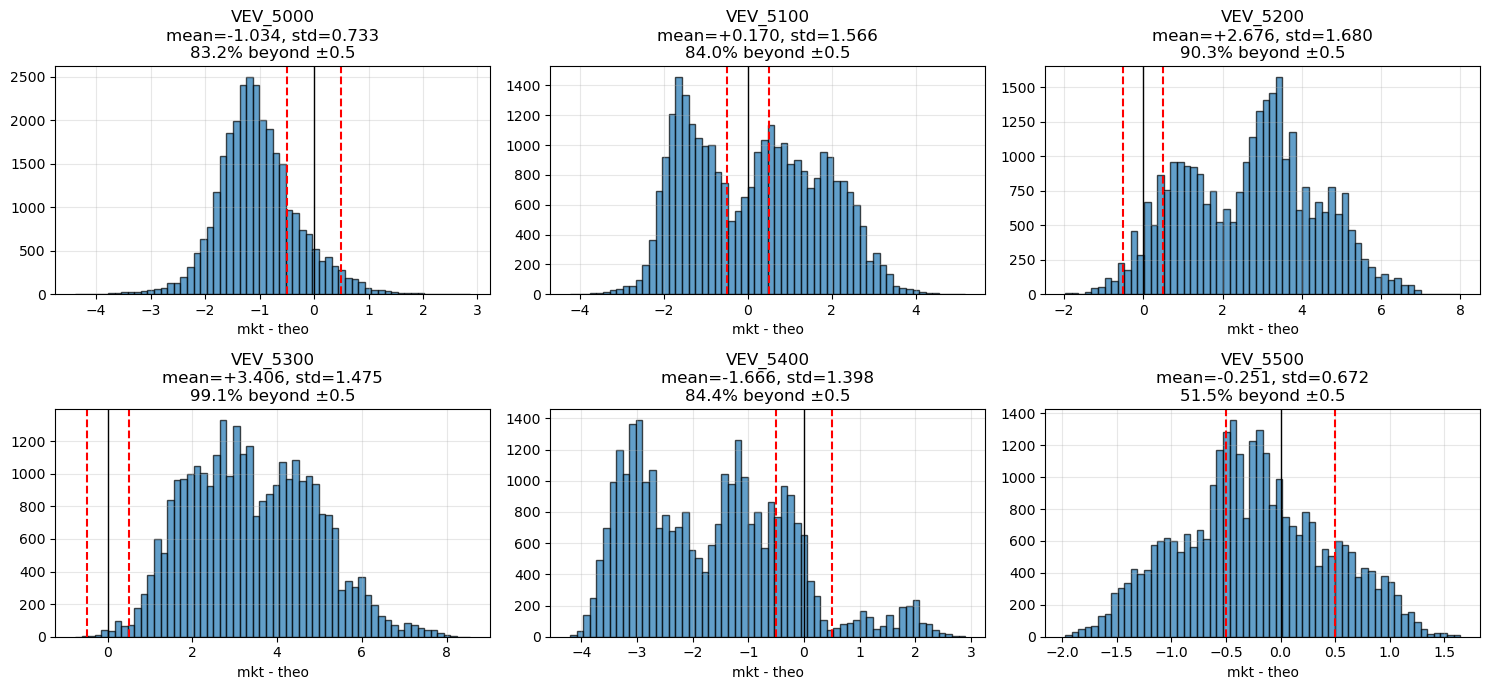

In [ ]:
# Per-strike theo_diff distribution
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, K in zip(axes.flat, [5000, 5100, 5200, 5300, 5400, 5500]):
    sub = theo_df[theo_df['K'] == K]['theo_diff']
    if len(sub) == 0:
        continue
    ax.hist(sub, bins=60, edgecolor='black', alpha=0.7)
    ax.axvline(0, color='k', lw=1)
    ax.axvline(0.5, color='red', ls='--', label='+0.5 (THR_OPEN)')
    ax.axvline(-0.5, color='red', ls='--')
    pct = (sub.abs() > 0.5).mean() * 100
    ax.set_title(f'VEV_{K}\nmean={sub.mean():+.3f}, std={sub.std():.3f}\n{pct:.1f}% beyond ±0.5')
    ax.set_xlabel('mkt - theo')
plt.tight_layout()

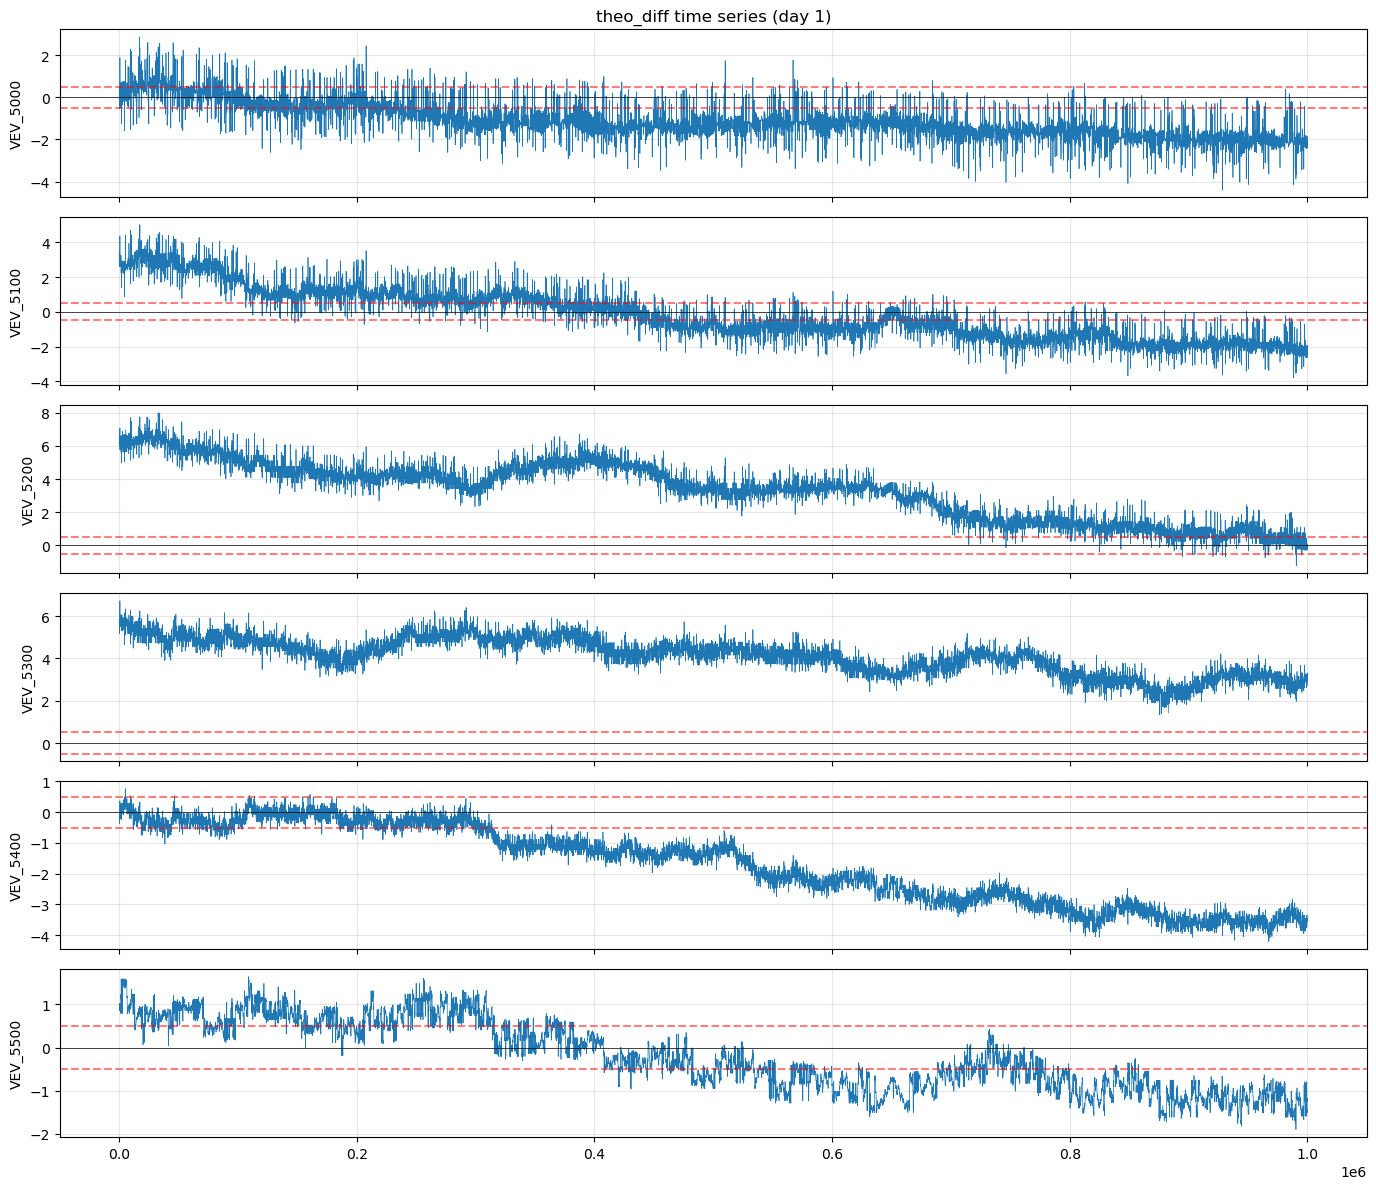

In [ ]:
# Time series of theo_diff per strike (one full day)
fig, axes = plt.subplots(6, 1, figsize=(14, 12), sharex=True)
day_to_show = 1
for ax, K in zip(axes, [5000, 5100, 5200, 5300, 5400, 5500]):
    sub = theo_df[(theo_df['day'] == day_to_show) & (theo_df['K'] == K)].sort_values('timestamp')
    ax.plot(sub['timestamp'], sub['theo_diff'], lw=0.5)
    ax.axhline(0, color='k', lw=0.5)
    ax.axhline(0.5, color='red', ls='--', alpha=0.5)
    ax.axhline(-0.5, color='red', ls='--', alpha=0.5)
    ax.set_ylabel(f'VEV_{K}')
axes[0].set_title(f'theo_diff time series (day {day_to_show})')
plt.tight_layout()

In [ ]:
# Verify mean reversion of theo_diff (the basic premise of IV scalping)
# Lag-1 autocorrelation of (theo_diff - EMA(theo_diff))
for K in [5000, 5100, 5200, 5300, 5400, 5500]:
    sub = theo_df[theo_df['K'] == K].sort_values(['day', 'timestamp'])
    if len(sub) < 100:
        continue
    td = sub['theo_diff'].values
    e = ema(td, 20)  # THEO_NORM_WINDOW = 20
    dev = td - e
    # autocorr of deviation
    if len(dev) > 1:
        ac = np.corrcoef(dev[:-1], dev[1:])[0, 1]
        # next-step return of theo_diff vs current deviation
        next_change = np.diff(td)
        cur_dev = dev[:-1]
        beta = np.corrcoef(cur_dev, next_change)[0, 1]
        print(f'VEV_{K}: dev autocorr = {ac:+.3f}, dev → next Δtd corr = {beta:+.3f} (negative = mean reverting)')

VEV_5000: dev autocorr = -0.041, dev → next Δtd corr = -0.687 (negative = mean reverting)
VEV_5100: dev autocorr = -0.011, dev → next Δtd corr = -0.675 (negative = mean reverting)
VEV_5200: dev autocorr = +0.023, dev → next Δtd corr = -0.661 (negative = mean reverting)
VEV_5300: dev autocorr = +0.078, dev → next Δtd corr = -0.638 (negative = mean reverting)
VEV_5400: dev autocorr = +0.229, dev → next Δtd corr = -0.570 (negative = mean reverting)
VEV_5500: dev autocorr = +0.580, dev → next Δtd corr = -0.370 (negative = mean reverting)


## 7. Trade flow analysis

In [ ]:
# Stack all trades, summarise volume per product per day
trades_all = pd.concat([trades[d].assign(day=d) for d in DAYS], ignore_index=True)
trade_summary = trades_all.groupby(['symbol', 'day']).agg(
    n_trades=('price', 'count'),
    total_qty=('quantity', 'sum'),
    avg_price=('price', 'mean'),
    avg_size=('quantity', 'mean'),
).round(2)
trade_summary

n_trades  total_qty  avg_price  avg_size
symbol              day                                          
HYDROGEL_PACK       0         324       1349    9990.55      4.16
                    1         375       1485    9993.61      3.96
                    2         311       1244    9986.66      4.00
VELVETFRUIT_EXTRACT 0         445       2689    5246.08      6.04
                    1         450       2685    5247.21      5.97
                    2         477       2895    5257.66      6.07
VEV_4000            0         172        351    1247.92      2.04
                    1         164        333    1247.90      2.03
                    2         128        256    1254.80      2.00
VEV_4500            1           1          1     733.00      1.00
VEV_5000            1           1          1     238.00      1.00
VEV_5100            1           1          1     152.00      1.00
VEV_5200            0           3         15      89.00      5.00
                    1           7         22      86.29      3.14
                    2           8         26      83.00      3.25
VEV_5300            0          37        128      45.92      3.46
                    1          39        130      44.18      3.33
                    2          45        162      42.69      3.60
VEV_5400            0          64        218      17.45      3.41
                    1          81        286      14.85      3.53
                    2          80        283      12.86      3.54
VEV_5500            0          81        281       7.27      3.47
                    1          92        321       5.99      3.49
                    2          94        335       4.78      3.56
VEV_6000            0          91        320       0.00      3.52
                    1          98        345       0.00      3.52
                    2          95        337       0.00      3.55
VEV_6500            0          91        320       0.00      3.52
                    1          98        345       0.00      3.52
                    2          95        337       0.00      3.55

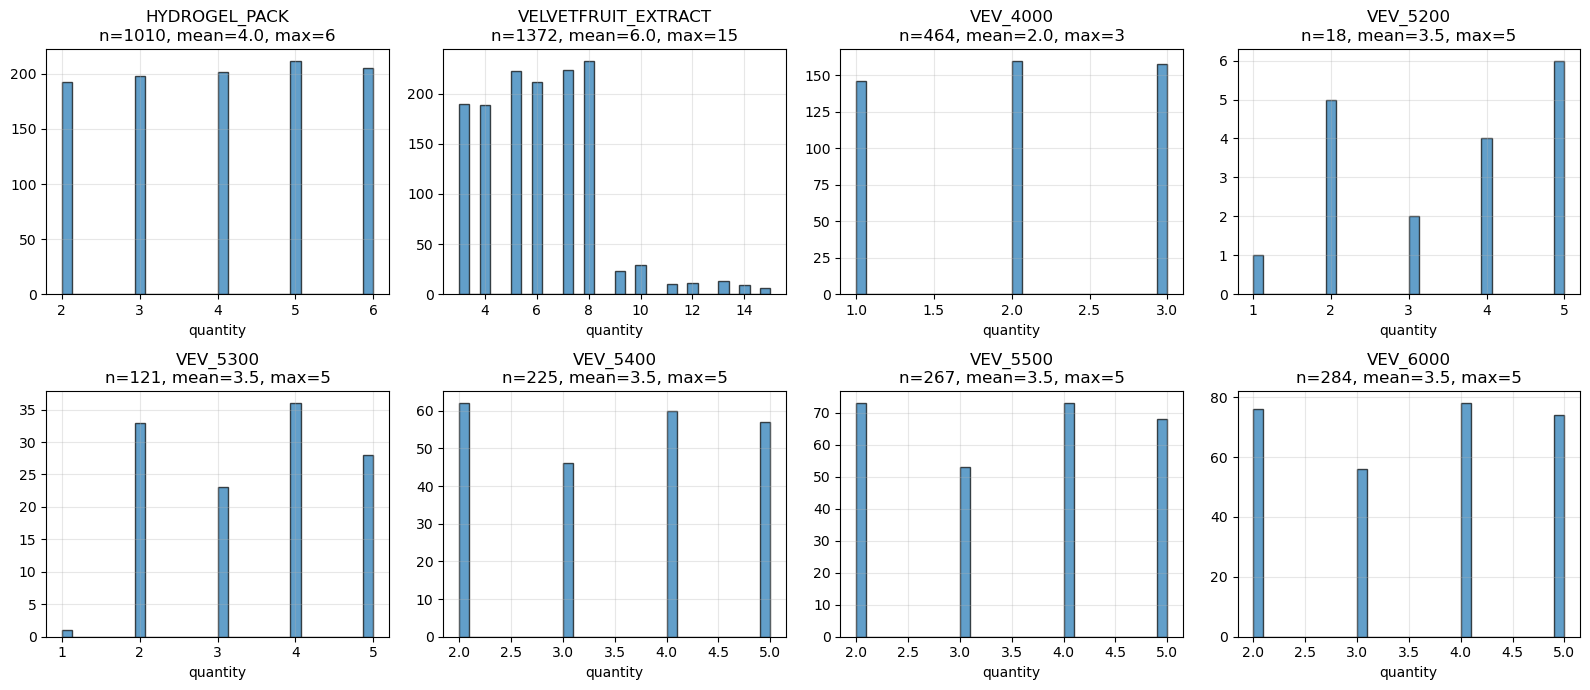

In [ ]:
# Trade size distribution per product (which products have big institutional prints?)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, prod in zip(axes.flat, [HYDROGEL, UNDERLYING] + [f'VEV_{k}' for k in [4000, 5200, 5300, 5400, 5500, 6000]]):
    sub = trades_all[trades_all['symbol'] == prod]['quantity']
    if len(sub) == 0:
        ax.set_visible(False)
        continue
    ax.hist(sub, bins=30, edgecolor='black', alpha=0.7)
    ax.set_title(f'{prod}\nn={len(sub)}, mean={sub.mean():.1f}, max={sub.max()}')
    ax.set_xlabel('quantity')
plt.tight_layout()

In [ ]:
# Are there informed trader IDs? (Round 3 packet has all NaN — verify)
print('Buyer / seller field unique values:')
print('  buyers:', trades_all['buyer'].unique())
print('  sellers:', trades_all['seller'].unique())
print('\n=> No informed-trader signal in this round\'s packet.')
print('   The strategy does not use check_for_informed for any product.')

Buyer / seller field unique values:
  buyers: [nan]
  sellers: [nan]

=> No informed-trader signal in this round's packet.
   The strategy does not use check_for_informed for any product.


## 8. Strategy parameter sweeps

Quick "what would have happened" backtests against historical data. These are *not* full backtests (no slippage, no queue position, no liquidity model) — just signal-quality checks.

In [ ]:
# Sweep: what fraction of theo_diff observations cross various THR_OPEN thresholds?
# Higher fraction = more frequent trades; combined with low signal-noise, more PnL.
results = []
for K in [5000, 5100, 5200, 5300, 5400, 5500]:
    sub = theo_df[theo_df['K'] == K].sort_values(['day', 'timestamp'])
    if len(sub) < 100:
        continue
    td = sub['theo_diff'].values
    e = ema(td, 20)
    dev = td - e
    for thr in [0.3, 0.5, 0.7, 1.0, 1.5, 2.0]:
        signal = (np.abs(dev) > thr)
        # Naive expected edge: (theo_diff - mean) reverts → next-period change opposite sign
        next_chg = np.diff(td)
        cur_dev = dev[:-1]
        signal_t = signal[:-1]
        if signal_t.sum() == 0:
            continue
        # Edge per signal: -mean(sign(dev) * next_chg) when signal active
        edge = (-np.sign(cur_dev[signal_t]) * next_chg[signal_t]).mean()
        results.append({
            'K': K, 'thr': thr,
            'pct_signals': round(signal.mean() * 100, 1),
            'avg_edge_per_signal': round(edge, 4),
        })
sweep_df = pd.DataFrame(results)
print(sweep_df.pivot(index='thr', columns='K', values='pct_signals').round(1))
print('\nAvg edge per signal (price units):')
print(sweep_df.pivot(index='thr', columns='K', values='avg_edge_per_signal').round(3))

K    5000  5100  5200  5300  5400  5500
thr                                    
0.3  36.1  32.3  31.9  26.2   6.7   8.2
0.5  16.1  13.3  11.8   6.1   0.6   1.3
0.7   9.4   8.1   5.7   2.0   0.1   0.1
1.0   6.7   5.0   2.3   0.2   0.1   0.0
1.5   2.2   0.9   0.1   0.1   0.1   NaN
2.0   0.2   0.1   0.0   0.1   0.0   NaN

Avg edge per signal (price units):
K     5000   5100   5200   5300   5400   5500
thr                                          
0.3  0.653  0.601  0.523  0.430  0.297  0.143
0.5  1.009  0.949  0.784  0.645  0.437  0.169
0.7  1.340  1.207  1.028  0.838  0.083  0.167
1.0  1.534  1.386  1.236  0.696  0.016 -0.021
1.5  1.863  1.656  1.085  0.011 -0.018    NaN
2.0  2.309  1.541  0.097  0.046  0.029    NaN


In [ ]:
# Crude PnL-per-signal estimate as we vary the EMA window for theo_diff
# (the strategy's THEO_NORM_WINDOW = 20)
rows = []
for K in [5100, 5200, 5300, 5400, 5500]:
    sub = theo_df[theo_df['K'] == K].sort_values(['day', 'timestamp'])
    if len(sub) < 200:
        continue
    td = sub['theo_diff'].values
    next_chg = np.diff(td)
    for window in [5, 10, 20, 30, 50, 100]:
        e = ema(td, window)
        dev = td - e
        signal = (np.abs(dev) > 0.5)[:-1]
        cur_dev = dev[:-1]
        if signal.sum() == 0:
            continue
        edge = (-np.sign(cur_dev[signal]) * next_chg[signal]).mean()
        rows.append({
            'K': K, 'window': window,
            'n_signals': int(signal.sum()),
            'edge_per_signal': round(edge, 4),
        })
win_df = pd.DataFrame(rows)
print('Edge per signal as a function of THEO_NORM_WINDOW:')
print(win_df.pivot(index='window', columns='K', values='edge_per_signal').round(3))

Edge per signal as a function of THEO_NORM_WINDOW:
K        5100   5200   5300   5400   5500
window                                   
5       1.054  0.917  0.791  0.366  0.294
10      0.976  0.834  0.702  0.491  0.186
20      0.949  0.784  0.645  0.437  0.169
30      0.929  0.760  0.626  0.391  0.162
50      0.896  0.728  0.582  0.352  0.153
100     0.833  0.674  0.530  0.294  0.138


In [ ]:
# Final summary: tableau for tuning
print('=== STRATEGY PARAMETER REFERENCE ===\n')
print('Currently in strategy (FrankfurtHedgehogs_round3.py):')
print('  SMILE_COEFFS         = [0.17620, -0.00068, 0.22261]')
print('  THEO_NORM_WINDOW     = 20')
print('  IV_SCALPING_THR      = 0.7')
print('  IV_SCALPING_WINDOW   = 100')
print('  THR_OPEN             = 0.5')
print('  THR_CLOSE            = 0.0')
print('  underlying_mr_thr    = 8 (window=10)')
print('  options_mr_thr       = 4 (window=30)')
print('  STATIC_MR_THR        = 12 (window=10) for HYDROGEL_PACK')
print('\nThings to verify / tune above:')
print('  1. Re-fit smile across all days vs day 2 only — does the curvature hold?')
print('  2. Pct of theo_diff outside ±0.5 should be ~10-30% per traded strike.')
print('  3. Edge per signal should be positive (signs match) for a viable IV scalp.')
print('  4. EMA dev for HYDROGEL/VEV crossing thresholds: target ~5-15% of bars.')

=== STRATEGY PARAMETER REFERENCE ===

Currently in strategy (FrankfurtHedgehogs_round3.py):
  SMILE_COEFFS         = [0.17620, -0.00068, 0.22261]
  THEO_NORM_WINDOW     = 20
  IV_SCALPING_THR      = 0.7
  IV_SCALPING_WINDOW   = 100
  THR_OPEN             = 0.5
  THR_CLOSE            = 0.0
  underlying_mr_thr    = 8 (window=10)
  options_mr_thr       = 4 (window=30)
  STATIC_MR_THR        = 12 (window=10) for HYDROGEL_PACK

Things to verify / tune above:
  1. Re-fit smile across all days vs day 2 only — does the curvature hold?
  2. Pct of theo_diff outside ±0.5 should be ~10-30% per traded strike.
  3. Edge per signal should be positive (signs match) for a viable IV scalp.
  4. EMA dev for HYDROGEL/VEV crossing thresholds: target ~5-15% of bars.
